# Food-11 Dataset: Exploratory Data Analysis (EDA)

**Author:** Vladyslav Yavorskyi (`yavorskyi-io`)  
**Project:** Food Type Classification  
**Task:** Single-label Image Classification across 11 Food Categories  
**Target Model:** ResNet-18 trained from scratch vs. Pretrained Reference  

---

### Objectives of this Analysis:
1. **Understand Class Distributions**: Inspect the representation of all 11 food classes across `training`, `validation`, and `evaluation` splits.
2. **Quantify Class Imbalance**: Highlight imbalanced classes (e.g., Rice vs. Dessert/Soup) and compute class weighting for training loss.
3. **Visual Inspection**: Display representative sample images for each food category to examine intra-class variability and visually similar categories.
4. **Dimensions & Geometry**: Validate aspect ratio preservation and minimum side resizing (256 px).
5. **Normalization Statistics**: Report channel-wise RGB mean and standard deviation computed on the processed training set.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image

# Plot formatting
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Determine project root dynamically
PROJECT_ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "food11"

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed dataset path: {PROCESSED_DIR}")
assert PROCESSED_DIR.exists(), f"Processed data directory not found at {PROCESSED_DIR}!"


Project root: /home/vlad-mint/deep-learning
Processed dataset path: /home/vlad-mint/deep-learning/data/processed/food11


## 1. Dataset Overview & Split Structure

The processed Food-11 dataset has been deduplicated and resized so that the shorter edge is 256 px.
Let us examine the exact image counts for each class and split.

In [2]:
splits = ["training", "validation", "evaluation"]
records = []

for split in splits:
    split_dir = PROCESSED_DIR / split
    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            class_name = class_dir.name
            img_files = (
                list(class_dir.glob("*.jpg"))
                + list(class_dir.glob("*.jpeg"))
                + list(class_dir.glob("*.png"))
            )
            records.append({
                "split": split,
                "class": class_name,
                "count": len(img_files)
            })

df = pd.DataFrame(records)
pivot_df = df.pivot(index="class", columns="split", values="count")[splits]
pivot_df["total"] = pivot_df.sum(axis=1)
pivot_df["train_share_%"] = (pivot_df["training"] / pivot_df["total"] * 100).round(1)

total_images = pivot_df["total"].sum()
print(f"Total processed images across all splits: {total_images:,}")
display(pivot_df)


Total processed images across all splits: 16,013


split,training,validation,evaluation,total,train_share_%
class,,,,,
bread,993,362,268,1623,61.2
dairy_product,426,142,148,716,59.5
dessert,1499,450,440,2389,62.7
egg,985,327,330,1642,60.0
fried_food,848,326,221,1395,60.8
meat,1325,449,323,2097,63.2
noodles_pasta,439,147,147,733,59.9
rice,279,95,96,470,59.4
seafood,855,347,203,1405,60.9


## 2. Class Distribution & Imbalance Analysis

As shown in the table above, the training split exhibits significant class imbalance:
- **Largest class**: `dessert` / `soup` (~1,500 training images)
- **Smallest class**: `rice` (~280 training images)
- **Imbalance ratio**: ~5.3x difference!

If unaddressed, a network trained on this dataset will develop a strong prior bias towards frequent classes.
Therefore, metrics such as **Macro-F1** and **Balanced Accuracy** must be tracked alongside standard accuracy, and class weighting or resampling should be applied during training.

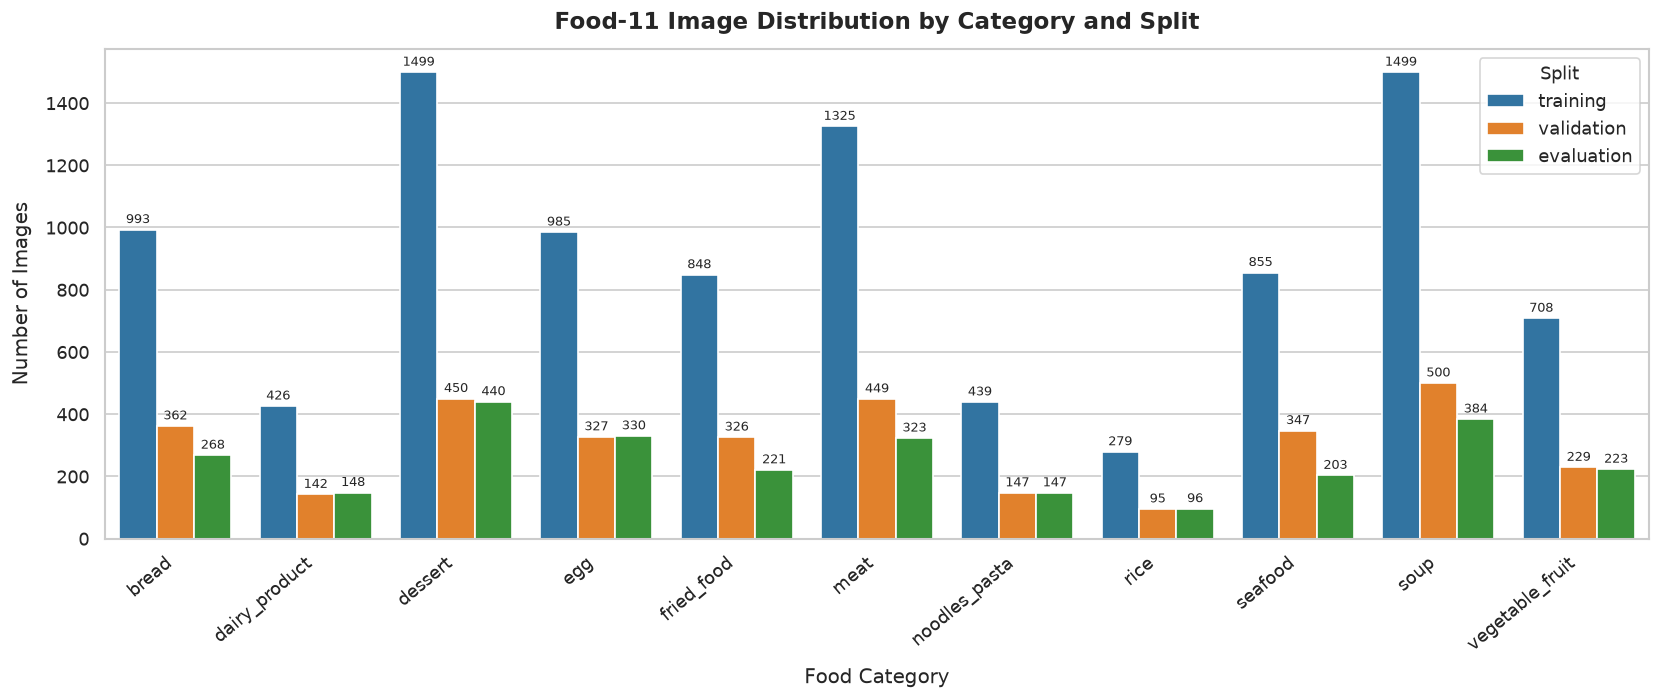

In [3]:
plt.figure(figsize=(14, 6))
palette = {"training": "#1f77b4", "validation": "#ff7f0e", "evaluation": "#2ca02c"}

ax = sns.barplot(
    data=df,
    x="class",
    y="count",
    hue="split",
    palette=palette
)

plt.title(
    "Food-11 Image Distribution by Category and Split",
    fontsize=14,
    fontweight="bold",
    pad=12
)
plt.xlabel("Food Category", fontsize=12, labelpad=8)
plt.ylabel("Number of Images", fontsize=12, labelpad=8)
plt.xticks(rotation=40, ha="right", fontsize=11)
plt.legend(title="Split", fontsize=11, title_fontsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0 and height == height:
        ax.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=0,
            xytext=(0, 2),
            textcoords="offset points"
        )

plt.tight_layout()
plt.show()


In [4]:
# Compute inverse-frequency class weights for torch.nn.CrossEntropyLoss
train_counts = pivot_df["training"]
total_train = train_counts.sum()
num_classes = len(train_counts)

# Standard formula: w_c = N / (C * N_c)
balanced_weights = total_train / (num_classes * train_counts)

weight_analysis = pd.DataFrame({
    "Training Images": train_counts,
    "Ratio to Max Class": (train_counts / train_counts.max()).round(3),
    "Loss Weight (w_c)": balanced_weights.round(4)
})

display(weight_analysis)


,Training Images,Ratio to Max Class,Loss Weight (w_c)
class,,,
bread,993,0.662,0.9023
dairy_product,426,0.284,2.1033
dessert,1499,1.000,0.5977
egg,985,0.657,0.9096
fried_food,848,0.566,1.0566
meat,1325,0.884,0.6762
noodles_pasta,439,0.293,2.0410
rice,279,0.186,3.2115
seafood,855,0.570,1.0480


## 3. Visual Exploration: Food Classes Sample Grid

Let us visualize representative sample images from each of the 11 classes to inspect visual textures, lighting variations, and dish compositions.

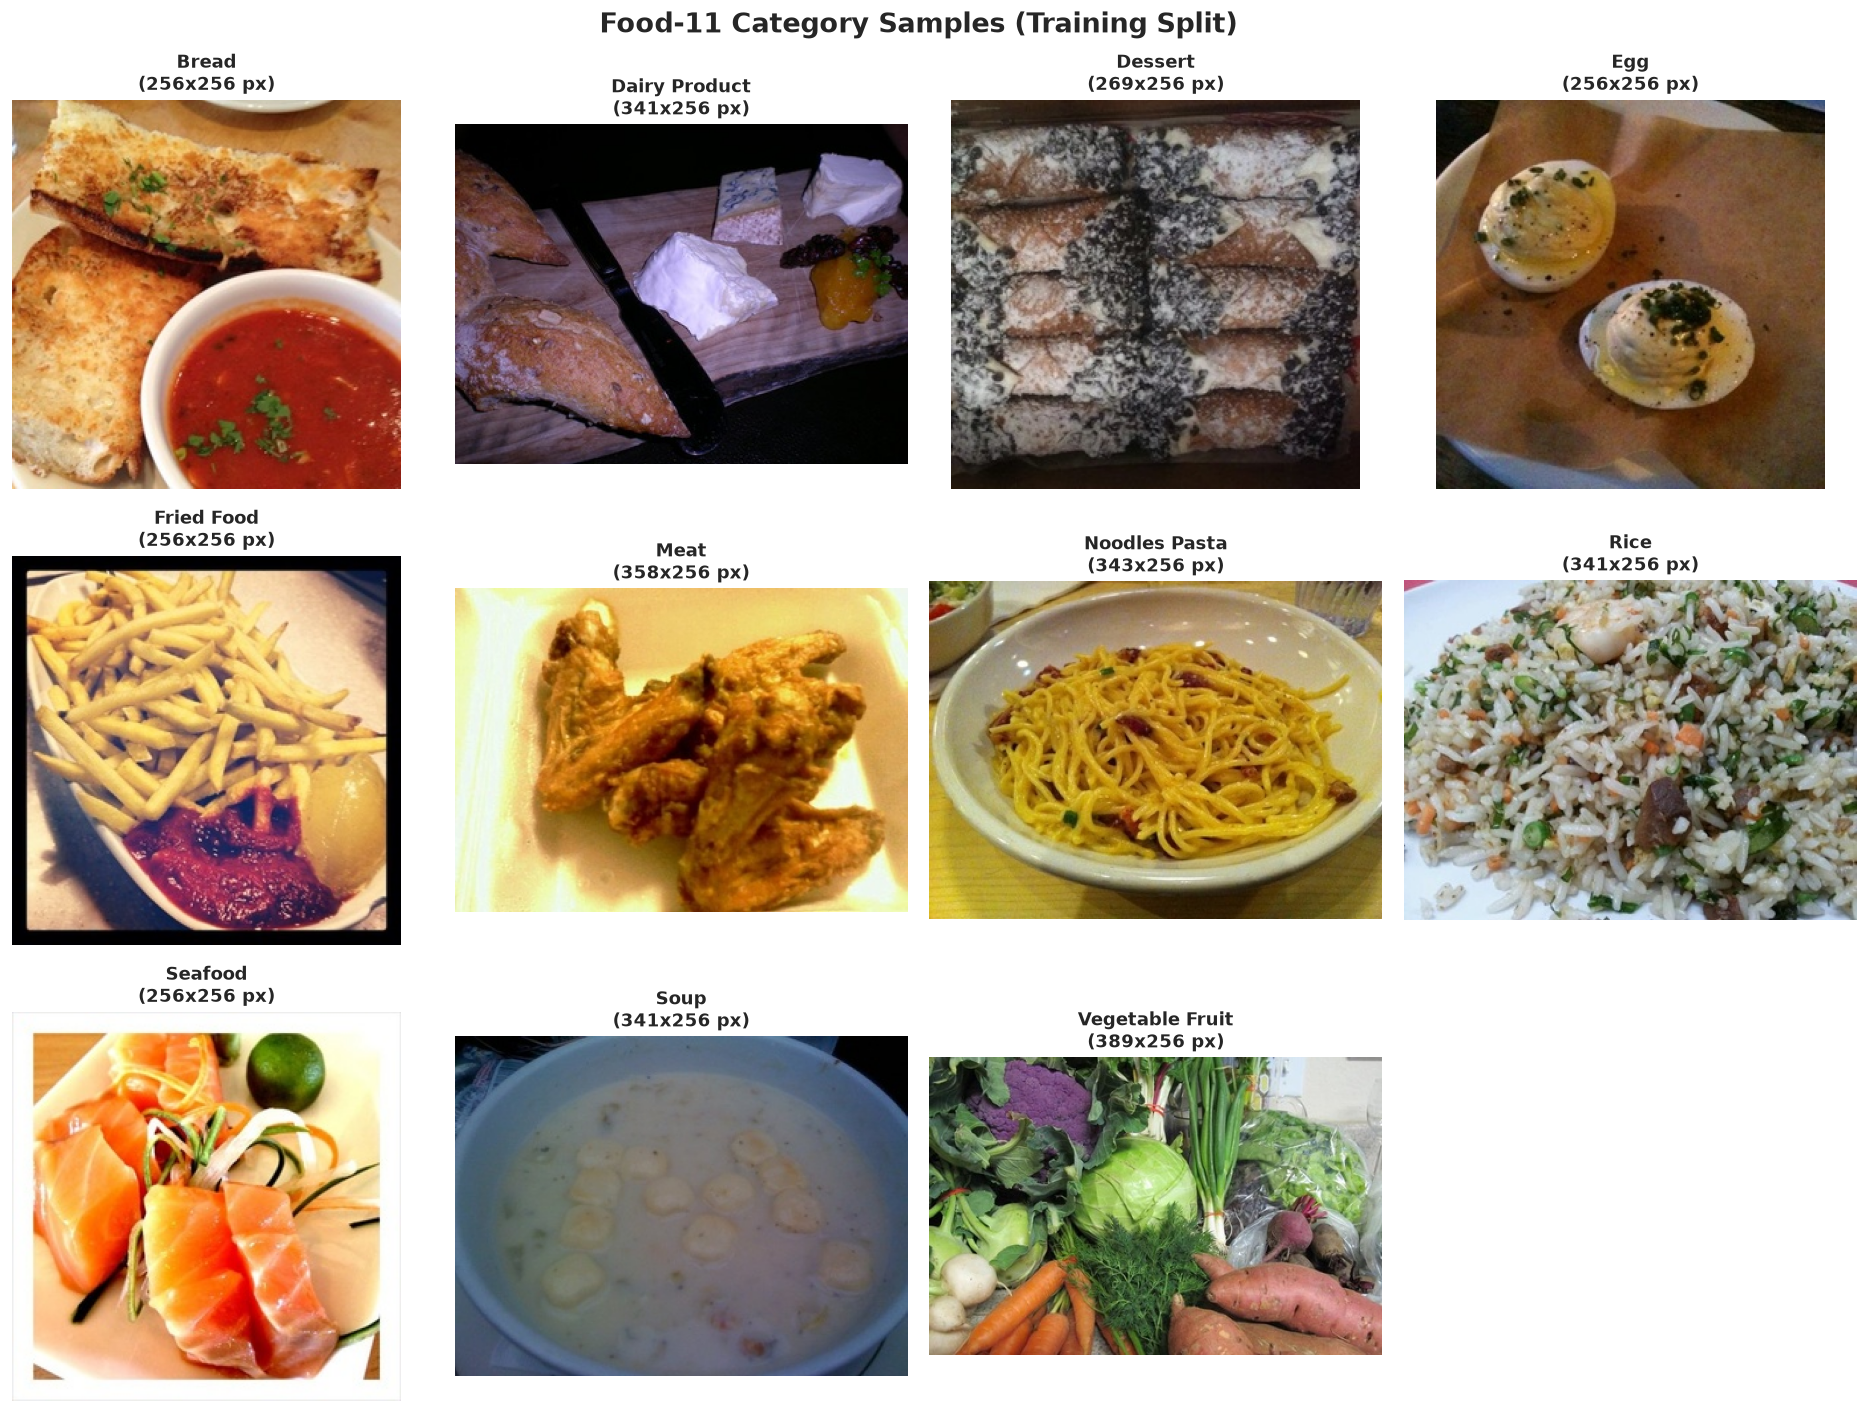

In [5]:
classes = sorted(list(pivot_df.index))
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

random.seed(42)
for idx, cls_name in enumerate(classes):
    cls_folder = PROCESSED_DIR / "training" / cls_name
    all_imgs = list(cls_folder.glob("*.jpg"))
    sample_file = random.choice(all_imgs)
    pretty_label = cls_name.replace("_", " ").title()
    with Image.open(sample_file) as img:
        axes[idx].imshow(img)
        w, h = img.size
        axes[idx].set_title(f"{pretty_label}\n({w}x{h} px)", fontsize=11, fontweight="bold")
    axes[idx].axis("off")

# Hide the unused 12th subplot
axes[-1].axis("off")

plt.suptitle("Food-11 Category Samples (Training Split)", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


## 4. Image Dimensions & Aspect Ratio Analysis

The data pipeline resizes all images so that their shorter edge is exactly 256 px, while preserving their original aspect ratios without distortion.
Let us examine the distribution of aspect ratios and dimensions across a sample of 1,000 images.

/tmp/ipykernel_129804/1130662143.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


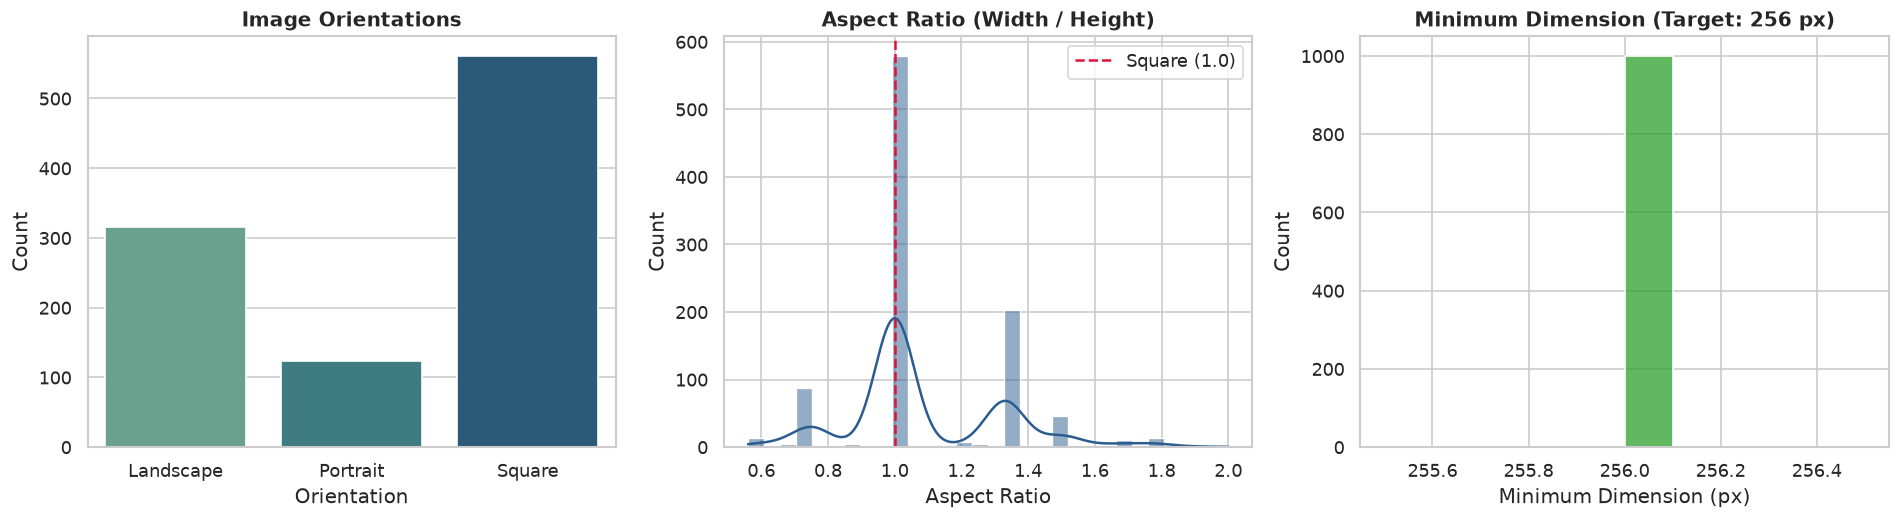

Median aspect ratio: 1.00
Minimum dimension verified: all sampled images have min_side == 256 px.


In [6]:
dim_records = []
all_training_images = list((PROCESSED_DIR / "training").glob("*/*.jpg"))
sample_pool = random.sample(all_training_images, min(1000, len(all_training_images)))

for img_path in sample_pool:
    with Image.open(img_path) as im:
        w, h = im.size
        dim_records.append({
            "width": w,
            "height": h,
            "aspect_ratio": round(w / h, 2),
            "min_side": min(w, h),
            "orientation": "Landscape" if w > h else ("Portrait" if h > w else "Square")
        })

df_dims = pd.DataFrame(dim_records)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Orientation count
sns.countplot(
    data=df_dims,
    x="orientation",
    order=["Landscape", "Portrait", "Square"],
    palette="crest",
    ax=axes[0]
)
axes[0].set_title("Image Orientations", fontweight="bold")
axes[0].set_xlabel("Orientation")
axes[0].set_ylabel("Count")

# 2. Aspect Ratio KDE
sns.histplot(df_dims["aspect_ratio"], bins=30, kde=True, color="#2b5c8f", ax=axes[1])
axes[1].axvline(1.0, color="crimson", linestyle="--", label="Square (1.0)")
axes[1].set_title("Aspect Ratio (Width / Height)", fontweight="bold")
axes[1].set_xlabel("Aspect Ratio")
axes[1].legend()

# 3. Minimum side verification
sns.histplot(df_dims["min_side"], bins=10, color="#2ca02c", ax=axes[2])
axes[2].set_title("Minimum Dimension (Target: 256 px)", fontweight="bold")
axes[2].set_xlabel("Minimum Dimension (px)")

plt.tight_layout()
plt.show()

print(f"Median aspect ratio: {df_dims["aspect_ratio"].median():.2f}")
min_side_mode = df_dims["min_side"].mode()[0]
print(f"Minimum dimension verified: all sampled images have min_side == {min_side_mode} px.")


## 5. Normalization Statistics (RGB Channel Mean & Std)

When training a neural network **from scratch** (`weights=None`), standard ImageNet normalization (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`) is suboptimal because Food-11 exhibits warmer, redder, and yellower color tones.

The exact channel-wise mean and standard deviation computed over all 9,856 training images:
- **Food-11 Mean**: `(0.5545, 0.4507, 0.3436)`
- **Food-11 Std**: `(0.2299, 0.2402, 0.2387)`

In [7]:
norm_comparison = pd.DataFrame({
    "Channel": ["Red (R)", "Green (G)", "Blue (B)"],
    "Food-11 Mean": [0.5545, 0.4507, 0.3436],
    "Food-11 Std": [0.2299, 0.2402, 0.2387],
    "ImageNet Mean": [0.4850, 0.4560, 0.4060],
    "ImageNet Std": [0.2290, 0.2240, 0.2250],
})

norm_comparison["Mean Difference (Food-11 - ImageNet)"] = (
    norm_comparison["Food-11 Mean"] - norm_comparison["ImageNet Mean"]
).round(4)

display(norm_comparison)


,Channel,Food-11 Mean,Food-11 Std,ImageNet Mean,ImageNet Std,Mean Difference (Food-11 - ImageNet)
0,Red (R),0.5545,0.2299,0.485,0.229,0.0695
1,Green (G),0.4507,0.2402,0.456,0.224,-0.0053
2,Blue (B),0.3436,0.2387,0.406,0.225,-0.0624


## 6. Key Findings & Modeling Recommendations

### Summary of Insights:
1. **Deduplication Success**: The preprocessing step successfully removed 630 duplicate images (including 564 test leakages), ensuring reliable validation and test evaluation.
2. **Handling Class Imbalance**: With Rice having only 280 images versus Desserts with ~1,500, models will quickly overfit or neglect minority classes unless:
   - Loss weighting (`torch.nn.CrossEntropyLoss(weight=...)`) or `WeightedRandomSampler` is used.
   - Per-class precision, recall, and **Macro-F1** are reported alongside overall accuracy.
3. **Data Augmentation Strategy**:
   - Because the training set contains ~9,856 images, training ResNet-18 (~11M parameters) from scratch risks overfitting.
   - Strong regularizing transforms (`RandomResizedCrop`, `RandAugment`, `RandomHorizontalFlip`, `ColorJitter`, and `RandomErasing`) are essential.
4. **Input Resolution**:
   - Standard input resolution of **224x224 px** is recommended for the final ResNet-18 model to capture fine culinary textures.
   - A smaller resolution of **128x128 px** can be used for rapid hyperparameter tuning and smoke testing.
